In [53]:
model_files = [
    "baseline_logistic_regression.joblib",
    "baseline_svm_linear.joblib",
    "baseline_random_forest.joblib",
    "baseline_xgboost.joblib",
    "baseline_lightgbm.joblib"
]

for file_name in model_files:
    path = PROJECT_ROOT / "models" / file_name
    print(file_name, ":", path.exists())

baseline_logistic_regression.joblib : True
baseline_svm_linear.joblib : True
baseline_random_forest.joblib : True
baseline_xgboost.joblib : True
baseline_lightgbm.joblib : True


In [52]:
import joblib

joblib.dump(
    logistic_model,
    PROJECT_ROOT / "models" / "baseline_logistic_regression.joblib"
)

joblib.dump(
    svm_model,
    PROJECT_ROOT / "models" / "baseline_svm_linear.joblib"
)

joblib.dump(
    rf_model,
    PROJECT_ROOT / "models" / "baseline_random_forest.joblib"
)

joblib.dump(
    xgb_model,
    PROJECT_ROOT / "models" / "baseline_xgboost.joblib"
)

joblib.dump(
    lgbm_model,
    PROJECT_ROOT / "models" / "baseline_lightgbm.joblib"
)

print("Les 5 modèles baseline ont été sauvegardés.")

Les 5 modèles baseline ont été sauvegardés.


## Sauvegarde des modèles de référence

In [51]:
xgb_learning_history = pd.DataFrame({
    "Iteration": range(1, len(train_loss) + 1),
    "Train_LogLoss": train_loss,
    "Validation_LogLoss": val_loss
})

xgb_learning_history.to_csv(
    METRICS_DIR / "baseline_xgboost_learning_history.csv",
    index=False
)

xgb_learning_history.head()

,Iteration,Train_LogLoss,Validation_LogLoss
0,1,0.016915,0.018792
1,2,0.005017,0.005984
2,3,0.004711,0.005721
3,4,0.004338,0.005387
4,5,0.004014,0.005151


In [50]:
print(
    (FIGURES_DIR / "baseline_xgboost_learning_curve.png").exists()
)

True


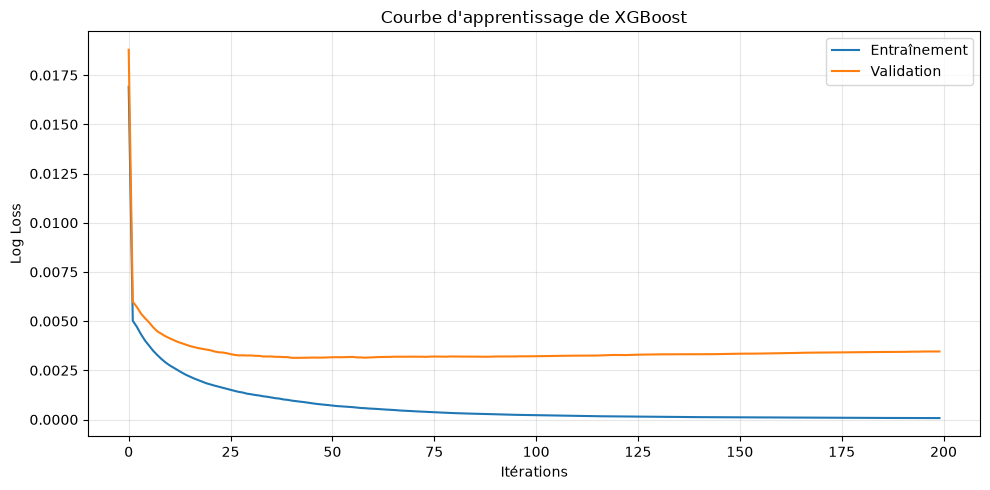

In [49]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    train_loss,
    label="Entraînement"
)

ax.plot(
    val_loss,
    label="Validation"
)

ax.set_xlabel("Itérations")
ax.set_ylabel("Log Loss")
ax.set_title("Courbe d'apprentissage de XGBoost")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "baseline_xgboost_learning_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

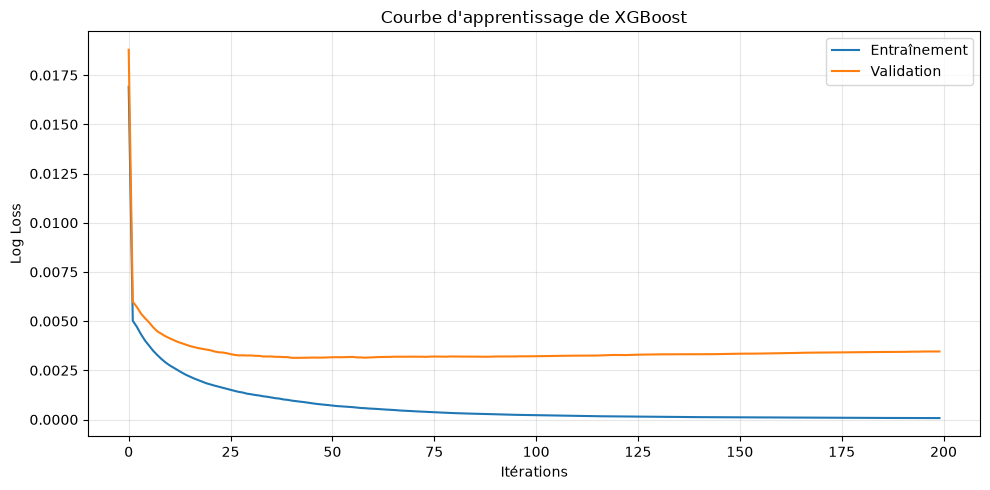

In [48]:
plt.figure(figsize=(10, 5))

plt.plot(train_loss, label="Entraînement")
plt.plot(val_loss, label="Validation")

plt.xlabel("Itérations")
plt.ylabel("Log Loss")
plt.title("Courbe d'apprentissage de XGBoost")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [47]:
xgb_history = xgb_curve_model.evals_result()

train_loss = xgb_history["validation_0"]["logloss"]
val_loss = xgb_history["validation_1"]["logloss"]

In [46]:
xgb_curve_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_curve_model.fit(
    X_train,
    y_train,
    eval_set=[
        (X_train, y_train),
        (X_val, y_val)
    ],
    verbose=False
)

print("Apprentissage pour la courbe XGBoost terminé.")

Apprentissage pour la courbe XGBoost terminé.


## Courbe d'apprentissage de XGBoost

L'évolution de la fonction de perte est observée sur les ensembles d'entraînement et de validation afin d'analyser le comportement du modèle au cours des itérations.

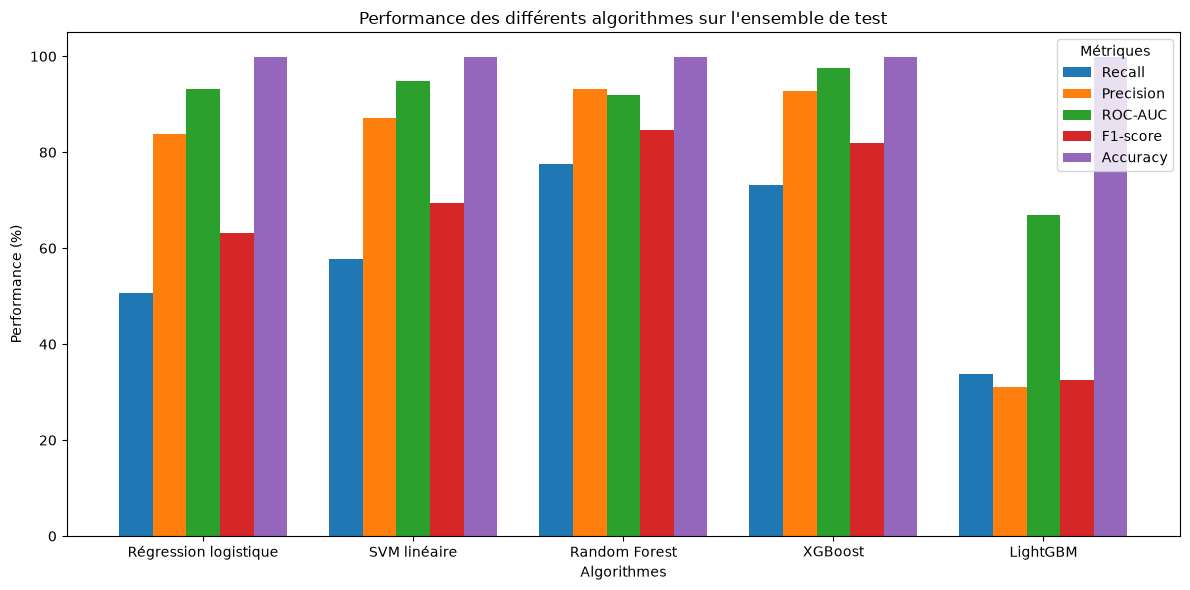

In [45]:
metrics_to_plot = [
    "Recall",
    "Precision",
    "ROC-AUC",
    "F1-score",
    "Accuracy"
]

plot_data = test_results[metrics_to_plot] * 100

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Performance des différents algorithmes sur l'ensemble de test")
ax.set_xlabel("Algorithmes")
ax.set_ylabel("Performance (%)")
ax.set_ylim(0, 105)

plt.xticks(rotation=0)
plt.legend(title="Métriques")
plt.tight_layout()

fig = ax.get_figure()

fig.savefig(
    FIGURES_DIR / "baseline_performance_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

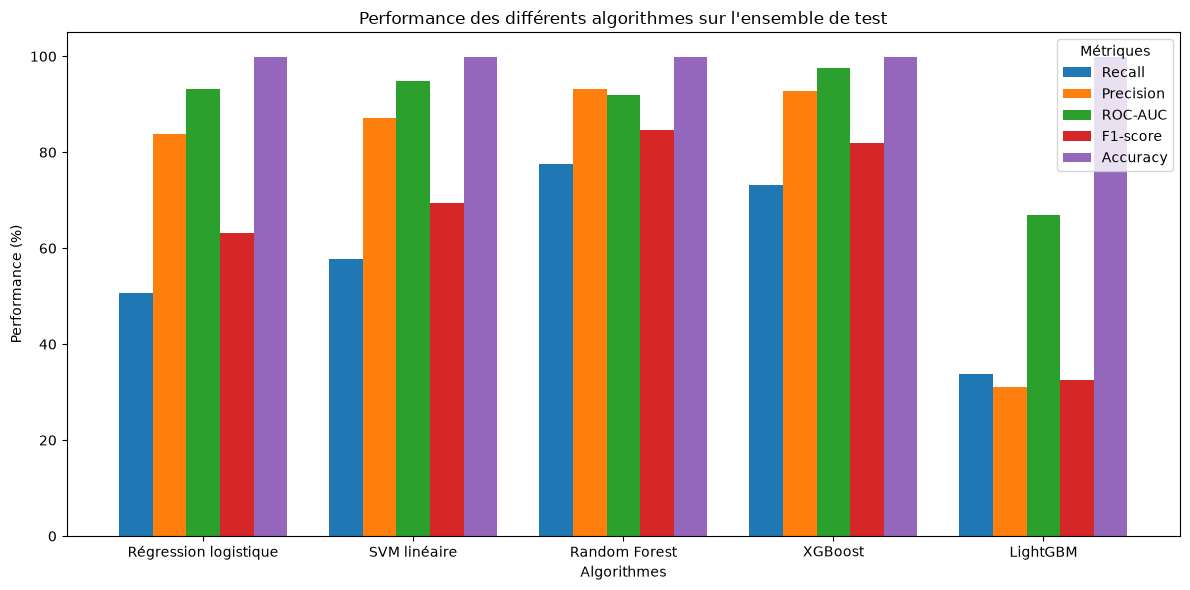

In [44]:
metrics_to_plot = [
    "Recall",
    "Precision",
    "ROC-AUC",
    "F1-score",
    "Accuracy"
]

plot_data = test_results[metrics_to_plot] * 100

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Performance des différents algorithmes sur l'ensemble de test")
ax.set_xlabel("Algorithmes")
ax.set_ylabel("Performance (%)")
ax.set_ylim(0, 105)

plt.xticks(rotation=0)
plt.legend(title="Métriques")
plt.tight_layout()
plt.show()

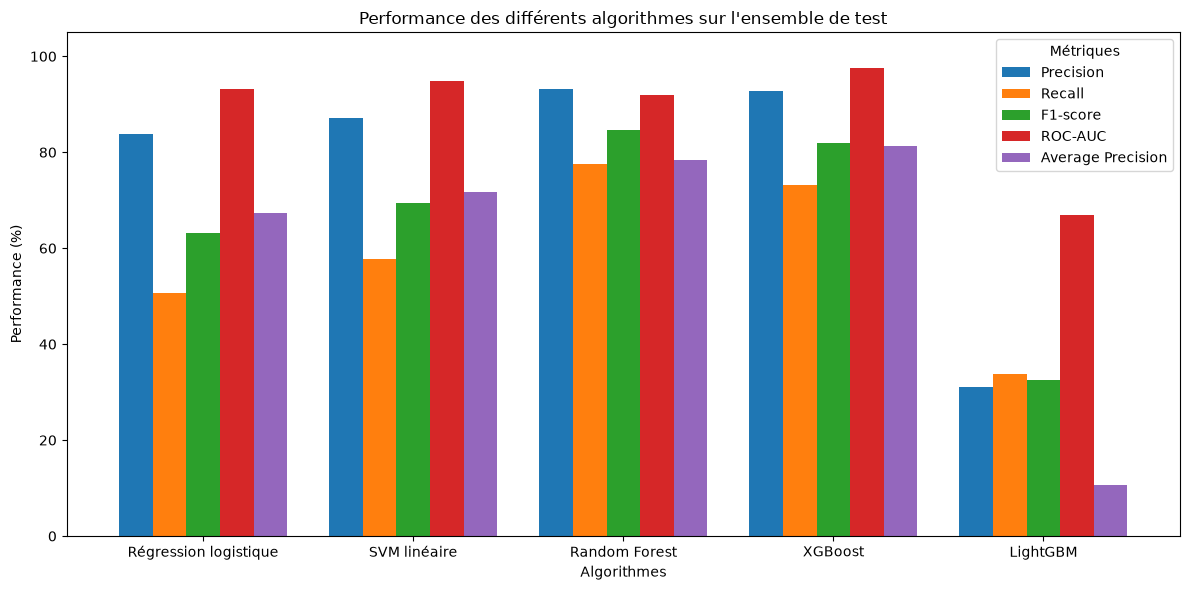

In [43]:
metrics_to_plot = [
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "Average Precision"
]

plot_data = test_results[metrics_to_plot] * 100

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Performance des différents algorithmes sur l'ensemble de test")
ax.set_xlabel("Algorithmes")
ax.set_ylabel("Performance (%)")
ax.set_ylim(0, 105)

plt.xticks(rotation=0)
plt.legend(title="Métriques")
plt.tight_layout()

plt.show()

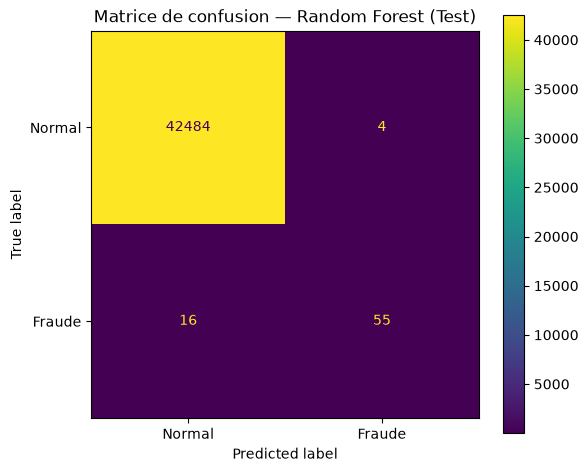

In [42]:
cm_rf_test = confusion_matrix(y_test, y_test_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf_test,
    display_labels=["Normal", "Fraude"]
)

fig, ax = plt.subplots(figsize=(6, 5))

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title("Matrice de confusion — Random Forest (Test)")

plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "baseline_confusion_random_forest.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Dossier des figures :", FIGURES_DIR)

Dossier des figures : c:\Users\MSI\Desktop\fraud_detection_memoire\results\figures


In [40]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

## Visualisation des matrices de confusion

In [39]:
print("Fichiers sauvegardés :")
print((METRICS_DIR / "baseline_test_metrics.csv").exists())
print((METRICS_DIR / "baseline_confusion_counts.csv").exists())

Fichiers sauvegardés :
True
True


In [38]:
confusion_test_results.to_csv(
    METRICS_DIR / "baseline_confusion_counts.csv",
    index=False
)

In [37]:
test_results.to_csv(
    METRICS_DIR / "baseline_test_metrics.csv",
    index=True
)

In [36]:
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"

METRICS_DIR.mkdir(parents=True, exist_ok=True)

print("Dossier métriques :", METRICS_DIR)

Dossier métriques : c:\Users\MSI\Desktop\fraud_detection_memoire\results\metrics


## Sauvegarde des résultats de la baseline

In [35]:
predictions_test = {
    "Régression logistique": y_test_pred_logistic,
    "SVM linéaire": y_test_pred_svm,
    "Random Forest": y_test_pred_rf,
    "XGBoost": y_test_pred_xgb,
    "LightGBM": y_test_pred_lgbm
}

confusion_test_results = []

for name, predictions in predictions_test.items():
    tn, fp, fn, tp = confusion_matrix(y_test, predictions).ravel()

    confusion_test_results.append({
        "Modèle": name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

confusion_test_results = pd.DataFrame(confusion_test_results)

confusion_test_results

,Modèle,TN,FP,FN,TP
0,Régression logistique,42481,7,35,36
1,SVM linéaire,42482,6,30,41
2,Random Forest,42484,4,16,55
3,XGBoost,42484,4,19,52
4,LightGBM,42435,53,47,24


In [34]:
test_results.style.format("{:.2%}").background_gradient(cmap="viridis")

,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Régression logistique,99.90%,75.34%,83.72%,50.70%,63.16%,93.19%,67.43%
SVM linéaire,99.92%,78.87%,87.23%,57.75%,69.49%,94.88%,71.77%
Random Forest,99.95%,88.73%,93.22%,77.46%,84.62%,91.92%,78.41%
XGBoost,99.95%,86.62%,92.86%,73.24%,81.89%,97.61%,81.32%
LightGBM,99.77%,66.84%,31.17%,33.80%,32.43%,66.83%,10.65%


In [33]:
test_results = pd.DataFrame({
    "Régression logistique": {
        "Accuracy": accuracy_score(y_test, y_test_pred_logistic),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_test_pred_logistic),
        "Precision": precision_score(y_test, y_test_pred_logistic, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred_logistic),
        "F1-score": f1_score(y_test, y_test_pred_logistic),
        "ROC-AUC": roc_auc_score(y_test, y_test_score_logistic),
        "Average Precision": average_precision_score(y_test, y_test_score_logistic)
    },

    "SVM linéaire": {
        "Accuracy": accuracy_score(y_test, y_test_pred_svm),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_test_pred_svm),
        "Precision": precision_score(y_test, y_test_pred_svm, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred_svm),
        "F1-score": f1_score(y_test, y_test_pred_svm),
        "ROC-AUC": roc_auc_score(y_test, y_test_score_svm),
        "Average Precision": average_precision_score(y_test, y_test_score_svm)
    },

    "Random Forest": {
        "Accuracy": accuracy_score(y_test, y_test_pred_rf),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_test_pred_rf),
        "Precision": precision_score(y_test, y_test_pred_rf, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred_rf),
        "F1-score": f1_score(y_test, y_test_pred_rf),
        "ROC-AUC": roc_auc_score(y_test, y_test_score_rf),
        "Average Precision": average_precision_score(y_test, y_test_score_rf)
    },

    "XGBoost": {
        "Accuracy": accuracy_score(y_test, y_test_pred_xgb),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_test_pred_xgb),
        "Precision": precision_score(y_test, y_test_pred_xgb, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred_xgb),
        "F1-score": f1_score(y_test, y_test_pred_xgb),
        "ROC-AUC": roc_auc_score(y_test, y_test_score_xgb),
        "Average Precision": average_precision_score(y_test, y_test_score_xgb)
    },

    "LightGBM": {
        "Accuracy": accuracy_score(y_test, y_test_pred_lgbm),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_test_pred_lgbm),
        "Precision": precision_score(y_test, y_test_pred_lgbm, zero_division=0),
        "Recall": recall_score(y_test, y_test_pred_lgbm),
        "F1-score": f1_score(y_test, y_test_pred_lgbm),
        "ROC-AUC": roc_auc_score(y_test, y_test_score_lgbm),
        "Average Precision": average_precision_score(y_test, y_test_score_lgbm)
    }
}).T

## Comparaison finale des performances sur l'ensemble de test

In [32]:
# Régression logistique
y_test_pred_logistic = logistic_model.predict(X_test)
y_test_score_logistic = logistic_model.predict_proba(X_test)[:, 1]

# SVM linéaire
y_test_pred_svm = svm_model.predict(X_test)
y_test_score_svm = svm_model.decision_function(X_test)

# Random Forest
y_test_pred_rf = rf_model.predict(X_test)
y_test_score_rf = rf_model.predict_proba(X_test)[:, 1]

# XGBoost
y_test_pred_xgb = xgb_model.predict(X_test)
y_test_score_xgb = xgb_model.predict_proba(X_test)[:, 1]

# LightGBM
y_test_pred_lgbm = lgbm_model.predict(X_test)
y_test_score_lgbm = lgbm_model.predict_proba(X_test)[:, 1]

print("Prédictions sur l'ensemble de test terminées.")

Prédictions sur l'ensemble de test terminées.


## Évaluation finale sur l'ensemble de test

Les modèles entraînés sont désormais évalués sur l'ensemble de test, conservé intact et jamais utilisé lors de l'apprentissage ou de la validation.

In [31]:
predictions_val = {
    "Régression logistique": y_val_pred_logistic,
    "SVM linéaire": y_val_pred_svm,
    "Random Forest": y_val_pred_rf,
    "XGBoost": y_val_pred_xgb,
    "LightGBM": y_val_pred_lgbm
}

confusion_results = []

for name, predictions in predictions_val.items():
    tn, fp, fn, tp = confusion_matrix(y_val, predictions).ravel()

    confusion_results.append({
        "Modèle": name,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

confusion_results = pd.DataFrame(confusion_results)

confusion_results

,Modèle,TN,FP,FN,TP
0,Régression logistique,42482,6,43,28
1,SVM linéaire,42483,5,39,32
2,Random Forest,42487,1,15,56
3,XGBoost,42488,0,23,48
4,LightGBM,42442,46,56,15


In [30]:
validation_results_styled = (
    validation_results.style
    .format("{:.2%}")
    .background_gradient(cmap="viridis")
)

validation_results_styled

,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Régression logistique,99.88%,69.71%,82.35%,39.44%,53.33%,96.73%,68.73%
SVM linéaire,99.90%,72.53%,86.49%,45.07%,59.26%,97.17%,71.60%
Random Forest,99.96%,89.44%,98.25%,78.87%,87.50%,93.36%,82.04%
XGBoost,99.95%,83.80%,100.00%,67.61%,80.67%,97.34%,82.51%
LightGBM,99.76%,60.51%,24.59%,21.13%,22.73%,60.50%,5.33%


In [29]:
validation_results = pd.DataFrame({
    "Régression logistique": logistic_val_metrics,
    "SVM linéaire": svm_val_metrics,
    "Random Forest": rf_val_metrics,
    "XGBoost": xgb_val_metrics,
    "LightGBM": lgbm_val_metrics
}).T

validation_results

,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Régression logistique,0.998849,0.697112,0.823529,0.394366,0.533333,0.967336,0.687287
SVM linéaire,0.998966,0.725293,0.864865,0.450704,0.592593,0.971729,0.715987
Random Forest,0.999624,0.894354,0.982456,0.788732,0.875000,0.933628,0.820418
XGBoost,0.999460,0.838028,1.000000,0.676056,0.806723,0.973375,0.825124
LightGBM,0.997603,0.605092,0.245902,0.211268,0.227273,0.605028,0.053267


## Comparaison des performances sur l'ensemble de validation

In [28]:
cm_lgbm = confusion_matrix(y_val, y_val_pred_lgbm)

cm_lgbm_df = pd.DataFrame(
    cm_lgbm,
    index=["Réel : Normal", "Réel : Fraude"],
    columns=["Prédit : Normal", "Prédit : Fraude"]
)

cm_lgbm_df

,Prédit : Normal,Prédit : Fraude
Réel : Normal,42442,46
Réel : Fraude,56,15


In [27]:
lgbm_val_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_lgbm),
    "Balanced Accuracy": balanced_accuracy_score(y_val, y_val_pred_lgbm),
    "Precision": precision_score(y_val, y_val_pred_lgbm, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_lgbm),
    "F1-score": f1_score(y_val, y_val_pred_lgbm),
    "ROC-AUC": roc_auc_score(y_val, y_val_score_lgbm),
    "Average Precision": average_precision_score(y_val, y_val_score_lgbm)
}

pd.DataFrame(
    lgbm_val_metrics.items(),
    columns=["Métrique", "Valeur"]
)

,Métrique,Valeur
0,Accuracy,0.997603
1,Balanced Accuracy,0.605092
2,Precision,0.245902
3,Recall,0.211268
4,F1-score,0.227273
5,ROC-AUC,0.605028
6,Average Precision,0.053267


In [26]:
y_val_pred_lgbm = lgbm_model.predict(X_val)

y_val_score_lgbm = lgbm_model.predict_proba(X_val)[:, 1]

In [25]:
lgbm_model = models["LightGBM"]

lgbm_model.fit(X_train, y_train)

print("Entraînement de LightGBM terminé.")

Entraînement de LightGBM terminé.


## 5. LightGBM

In [24]:
cm_xgb = confusion_matrix(y_val, y_val_pred_xgb)

cm_xgb_df = pd.DataFrame(
    cm_xgb,
    index=["Réel : Normal", "Réel : Fraude"],
    columns=["Prédit : Normal", "Prédit : Fraude"]
)

cm_xgb_df

,Prédit : Normal,Prédit : Fraude
Réel : Normal,42488,0
Réel : Fraude,23,48


In [23]:
xgb_val_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_xgb),
    "Balanced Accuracy": balanced_accuracy_score(y_val, y_val_pred_xgb),
    "Precision": precision_score(y_val, y_val_pred_xgb, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_xgb),
    "F1-score": f1_score(y_val, y_val_pred_xgb),
    "ROC-AUC": roc_auc_score(y_val, y_val_score_xgb),
    "Average Precision": average_precision_score(y_val, y_val_score_xgb)
}

pd.DataFrame(
    xgb_val_metrics.items(),
    columns=["Métrique", "Valeur"]
)

,Métrique,Valeur
0,Accuracy,0.999460
1,Balanced Accuracy,0.838028
2,Precision,1.000000
3,Recall,0.676056
4,F1-score,0.806723
5,ROC-AUC,0.973375
6,Average Precision,0.825124


In [22]:
y_val_pred_xgb = xgb_model.predict(X_val)

y_val_score_xgb = xgb_model.predict_proba(X_val)[:, 1]

In [21]:
xgb_model = models["XGBoost"]

xgb_model.fit(X_train, y_train)

print("Entraînement de XGBoost terminé.")

Entraînement de XGBoost terminé.


## 4. XGBoost

In [20]:
cm_rf = confusion_matrix(y_val, y_val_pred_rf)

cm_rf_df = pd.DataFrame(
    cm_rf,
    index=["Réel : Normal", "Réel : Fraude"],
    columns=["Prédit : Normal", "Prédit : Fraude"]
)

cm_rf_df

,Prédit : Normal,Prédit : Fraude
Réel : Normal,42487,1
Réel : Fraude,15,56


In [19]:
rf_val_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_rf),
    "Balanced Accuracy": balanced_accuracy_score(y_val, y_val_pred_rf),
    "Precision": precision_score(y_val, y_val_pred_rf, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_rf),
    "F1-score": f1_score(y_val, y_val_pred_rf),
    "ROC-AUC": roc_auc_score(y_val, y_val_score_rf),
    "Average Precision": average_precision_score(y_val, y_val_score_rf)
}

pd.DataFrame(
    rf_val_metrics.items(),
    columns=["Métrique", "Valeur"]
)

,Métrique,Valeur
0,Accuracy,0.999624
1,Balanced Accuracy,0.894354
2,Precision,0.982456
3,Recall,0.788732
4,F1-score,0.875000
5,ROC-AUC,0.933628
6,Average Precision,0.820418


In [18]:
y_val_pred_rf = rf_model.predict(X_val)

y_val_score_rf = rf_model.predict_proba(X_val)[:, 1]

In [17]:
rf_model = models["Random Forest"]

rf_model.fit(X_train, y_train)

print("Entraînement du Random Forest terminé.")

Entraînement du Random Forest terminé.


## 3. Random Forest

In [16]:
cm_svm = confusion_matrix(y_val, y_val_pred_svm)

cm_svm_df = pd.DataFrame(
    cm_svm,
    index=["Réel : Normal", "Réel : Fraude"],
    columns=["Prédit : Normal", "Prédit : Fraude"]
)

cm_svm_df

,Prédit : Normal,Prédit : Fraude
Réel : Normal,42483,5
Réel : Fraude,39,32


In [15]:
svm_val_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_svm),
    "Balanced Accuracy": balanced_accuracy_score(y_val, y_val_pred_svm),
    "Precision": precision_score(y_val, y_val_pred_svm, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_svm),
    "F1-score": f1_score(y_val, y_val_pred_svm),
    "ROC-AUC": roc_auc_score(y_val, y_val_score_svm),
    "Average Precision": average_precision_score(y_val, y_val_score_svm)
}

pd.DataFrame(
    svm_val_metrics.items(),
    columns=["Métrique", "Valeur"]
)

,Métrique,Valeur
0,Accuracy,0.998966
1,Balanced Accuracy,0.725293
2,Precision,0.864865
3,Recall,0.450704
4,F1-score,0.592593
5,ROC-AUC,0.971729
6,Average Precision,0.715987


In [14]:
y_val_pred_svm = svm_model.predict(X_val)

y_val_score_svm = svm_model.decision_function(X_val)

In [13]:
svm_model = models["SVM linéaire"]

svm_model.fit(X_train, y_train)

print("Entraînement du SVM linéaire terminé.")

Entraînement du SVM linéaire terminé.


## 2. SVM linéaire

In [12]:
cm_logistic = confusion_matrix(y_val, y_val_pred_logistic)

cm_logistic_df = pd.DataFrame(
    cm_logistic,
    index=["Réel : Normal", "Réel : Fraude"],
    columns=["Prédit : Normal", "Prédit : Fraude"]
)

cm_logistic_df

,Prédit : Normal,Prédit : Fraude
Réel : Normal,42482,6
Réel : Fraude,43,28


In [11]:
logistic_val_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred_logistic),
    "Balanced Accuracy": balanced_accuracy_score(y_val, y_val_pred_logistic),
    "Precision": precision_score(y_val, y_val_pred_logistic, zero_division=0),
    "Recall": recall_score(y_val, y_val_pred_logistic),
    "F1-score": f1_score(y_val, y_val_pred_logistic),
    "ROC-AUC": roc_auc_score(y_val, y_val_score_logistic),
    "Average Precision": average_precision_score(y_val, y_val_score_logistic)
}

pd.DataFrame(
    logistic_val_metrics.items(),
    columns=["Métrique", "Valeur"]
)

,Métrique,Valeur
0,Accuracy,0.998849
1,Balanced Accuracy,0.697112
2,Precision,0.823529
3,Recall,0.394366
4,F1-score,0.533333
5,ROC-AUC,0.967336
6,Average Precision,0.687287


In [10]:
y_val_pred_logistic = logistic_model.predict(X_val)

y_val_score_logistic = logistic_model.predict_proba(X_val)[:, 1]

In [9]:
logistic_model = models["Régression logistique"]

logistic_model.fit(X_train, y_train)

print("Entraînement de la Régression logistique terminé.")

Entraînement de la Régression logistique terminé.


## 1. Régression logistique

In [1]:
models = {
    "Régression logistique": LogisticRegression(
        max_iter=2000,
        class_weight=None,
        random_state=42
    ),

    "SVM linéaire": LinearSVC(
        C=1.0,
        class_weight=None,
        max_iter=5000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight=None,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=6,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=200,
        learning_rate=0.1,
        class_weight=None,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )
}

NameError: name 'LogisticRegression' is not defined

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

In [6]:
try:
    import xgboost
    print("XGBoost :", xgboost.__version__)
except ImportError:
    print("XGBoost : NON INSTALLÉ")

try:
    import lightgbm
    print("LightGBM :", lightgbm.__version__)
except ImportError:
    print("LightGBM : NON INSTALLÉ")

XGBoost : 3.4.1
LightGBM : 4.7.0


## Protocole d'évaluation

Les cinq classificateurs sont entraînés sur l'ensemble d'entraînement réel et déséquilibré, sans rééchantillonnage ni pondération automatique des classes. Les performances sont d'abord contrôlées sur l'ensemble de validation, puis mesurées sur l'ensemble de test conservé intact. Les métriques considérées sont l'Accuracy, la Balanced Accuracy, la Precision, le Recall, le F1-score, le ROC-AUC et le PR-AUC.

In [4]:
print("Train      :", X_train.shape, y_train.shape)
print("Validation :", X_val.shape, y_val.shape)
print("Test       :", X_test.shape, y_test.shape)

print("\nFraudes :")
print("Train      :", y_train.sum())
print("Validation :", y_val.sum())
print("Test       :", y_test.sum())

Train      : (198608, 30) (198608,)
Validation : (42559, 30) (42559,)
Test       : (42559, 30) (42559,)

Fraudes :
Train      : 331
Validation : 71
Test       : 71


In [3]:
X_train = pd.read_parquet(PROCESSED_DIR / "X_train.parquet")
X_val = pd.read_parquet(PROCESSED_DIR / "X_val.parquet")
X_test = pd.read_parquet(PROCESSED_DIR / "X_test.parquet")

y_train = pd.read_parquet(PROCESSED_DIR / "y_train.parquet")["Class"]
y_val = pd.read_parquet(PROCESSED_DIR / "y_val.parquet")["Class"]
y_test = pd.read_parquet(PROCESSED_DIR / "y_test.parquet")["Class"]

In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

print("Dossier du projet :", PROJECT_ROOT)
print("Données préparées :", PROCESSED_DIR)
print("Dossier trouvé :", PROCESSED_DIR.exists())

Dossier du projet : c:\Users\MSI\Desktop\fraud_detection_memoire
Données préparées : c:\Users\MSI\Desktop\fraud_detection_memoire\data\processed
Dossier trouvé : True


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# 03 — Évaluation Baseline

## Classification sur les données réelles déséquilibrées

Objectif : entraîner et évaluer plusieurs modèles de classification sur les données prétraitées, sans appliquer de technique de rééquilibrage ou d'augmentation, afin d'établir les performances de référence.